In [1]:
%pip install numpy matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
def ShowImage(image):
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.show()

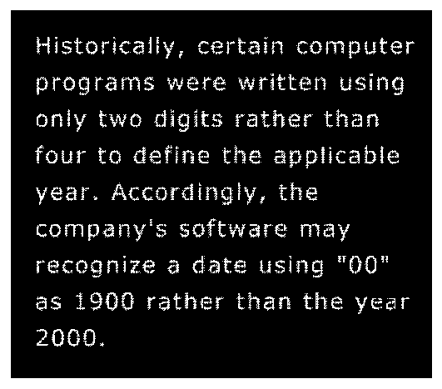

In [6]:
originalText = Image.open("Broken_Text.tif")
ShowImage(originalText)

In [7]:
# Load structural element
structuralElement = np.array([[0, 1, 0],
                              [1, 1, 1],
                              [0, 1, 0]], dtype=np.uint8)
print("Structural Element:")
print(structuralElement)

Structural Element:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


In [10]:
def dilate(image, struct_elem):
    img_height, img_width = image.shape
    se_height, se_width = struct_elem.shape
    
    pad_height = se_height // 2
    pad_width = se_width // 2
    
    # Pad the image with zeros to avoid boundary issues
    padded_image = np.pad(image, ((pad_height, pad_height), (pad_width, pad_width)), mode='constant', constant_values=0)
    
    dilated_image = np.zeros_like(padded_image)
    
    # Perform dilation
    for i in range(img_height):
        for j in range(img_width):
            if (image[i, j] == 1):
                dilated_image[i+pad_height, j+pad_width] = 1
                for m in range(se_height):
                    for n in range(se_width):
                        if struct_elem[m, n] == 1:
                            dilated_image[i + m, j + n] = 1
    
    return dilated_image

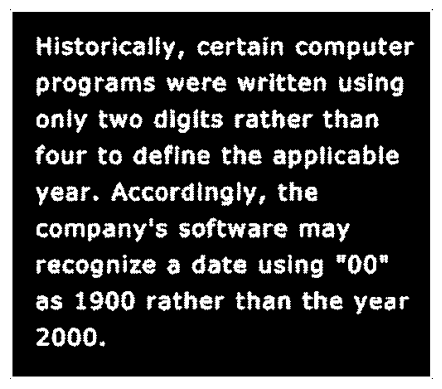

In [11]:
dilated_image = dilate(np.array(originalText), structuralElement)
ShowImage(dilated_image)

In [25]:
def erode(image, struct_elem):
    img_height, img_width = image.shape
    se_height, se_width = struct_elem.shape
    
    pad_height = se_height // 2
    pad_width = se_width // 2
    
    # Pad the image with zeros to avoid boundary issues
    padded_image = np.pad(image, ((pad_height, pad_height), (pad_width, pad_width)), mode='constant', constant_values=0)
    
    eroded_image = np.zeros_like(padded_image)
    
    # Perform erosion
    for i in range(img_height):
        for j in range(img_width):
            if (image[i, j] != 0):
                match = True
                for m in range(se_height):
                    for n in range(se_width):
                        if struct_elem[m, n] == 1 and padded_image[i + m - pad_height, j + n - pad_width] == 0:
                            match = False
                            break
                if match:
                    eroded_image[i + pad_height, j + pad_width] = 1
    
    return eroded_image

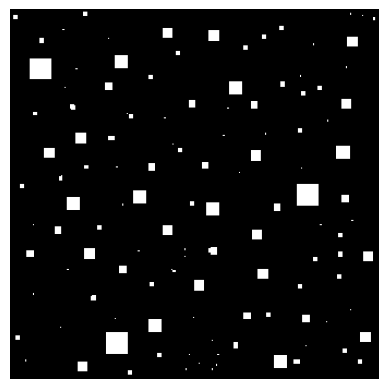

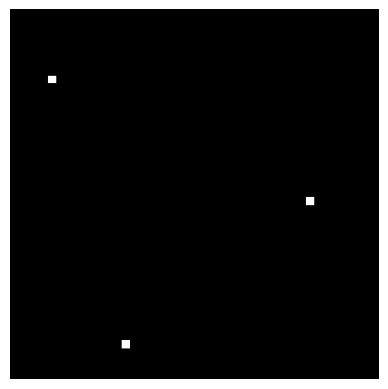

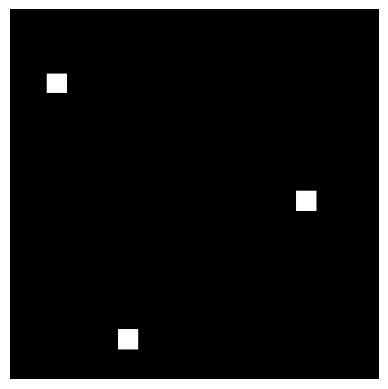

In [29]:
image2 = Image.open("Noisy_Squares.tif")
ShowImage(image2)
structuralElement2 = np.ones((13, 13), dtype=np.uint8)
eroded_image = erode(np.array(image2), structuralElement2)
ShowImage(eroded_image)
dilated_image2 = dilate(eroded_image, structuralElement2)
ShowImage(dilated_image2)

In [30]:
def aperture(image, struct_elem):
    eroded = erode(image, struct_elem)
    opened = dilate(eroded, struct_elem)
    return opened

In [31]:
def closure(image, struct_elem):
    dilated = dilate(image, struct_elem)
    closed = erode(dilated, struct_elem)
    return closed

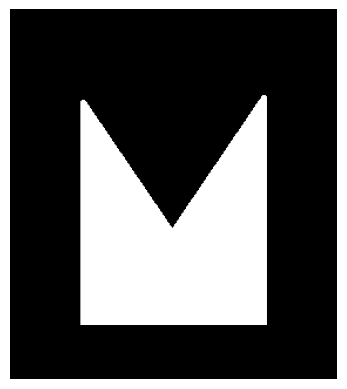

In [35]:
figure_b = Image.open("figure_B.bmp")
# To black and white
figure_b = figure_b.convert("1")
ShowImage(figure_b)

In [36]:
# Circle shaped structural element
def create_circle_struct_elem(radius):
    size = radius * 2 + 1
    struct_elem = np.zeros((size, size), dtype=np.uint8)
    center = radius
    
    for i in range(size):
        for j in range(size):
            if (i - center) ** 2 + (j - center) ** 2 <= radius ** 2:
                struct_elem[i, j] = 1
                
    return struct_elem

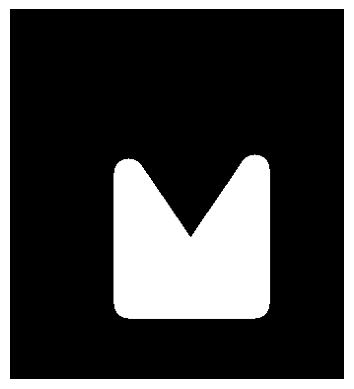

In [39]:
circle_struct_elem = create_circle_struct_elem(15)
aperture_result = aperture(np.array(figure_b), circle_struct_elem)
ShowImage(aperture_result)